# Homework 4: Evaluation Metrics for Machine Learning

**Course**: DataTalks.Club Machine Learning Zoomcamp (2026 Cohort)  
**Dataset**: [2026 Lead Scoring Dataset](../../data/course_lead_scoring_2026.csv)  
**Topic**: Binary Classification Evaluation (ROC AUC, Precision, Recall, F1-Score, K-Fold Cross Validation, Regularization Tuning)

---

### Homework Overview
In this homework, we evaluate binary classification models for predicting lead conversion (`converted`) using:
1. **Feature Importance with ROC AUC**: Assessing individual numerical predictive power.
2. **Model Training & ROC AUC**: Logistic regression validation ROC AUC.
3. **Precision & Recall Curves**: Finding the threshold where precision and recall intersect.
4. **F1-Score Maximization**: Determining the optimal threshold that balances precision and recall.
5. **K-Fold Cross-Validation**: Estimating model stability and standard deviation across 5 folds.
6. **Hyperparameter Tuning ($C$)**: Finding the regularization parameter that achieves the highest cross-validated ROC AUC.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)

# Set plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11


## Data Preparation

* Target variable: `converted` (1 = signed up to platform, 0 = not converted).
* Handle missing values:
  * For categorical features, replace missing values with `'NA'`.
  * For numerical features, replace missing values with `0.0`.
* Split data:
  * 60% Train, 20% Validation, 20% Test using `random_state=1`.


In [2]:
# Load the dataset
data_path = "../../data/course_lead_scoring_2026.csv"
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
print("\nMissing values per column:")
print(df.isnull().sum())

TARGET = "converted"

# Separate features from target
features = df.drop(columns=[TARGET]).copy()

categorical_features = features.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_features = features.select_dtypes(exclude=["object", "string"]).columns.tolist()

print(f"\nCategorical features ({len(categorical_features)}): {categorical_features}")
print(f"Numerical features ({len(numerical_features)}): {numerical_features}")

# Impute missing values
features[categorical_features] = features[categorical_features].fillna("NA")
features[numerical_features] = features[numerical_features].fillna(0.0)

# Re-attach target column
df_prepared = features.assign(**{TARGET: df[TARGET].to_numpy()})
print(f"\nMissing values after imputation: {df_prepared.isnull().sum().sum()}")


Dataset shape: (5000, 9)

Missing values per column:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Categorical features (4): ['lead_source', 'industry', 'employment_status', 'location']
Numerical features (4): ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

Missing values after imputation: 0


### Split the Data

Split the data into 3 parts with these exact calls:
```python
df_full_train, df_test = train_test_split(df_prepared, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
```


In [3]:
# Split full_train (80%) and test (20%)
df_full_train, df_test = train_test_split(df_prepared, test_size=0.2, random_state=1)

# Split full_train into train (60% of total) and validation (20% of total)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reset index
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Separate target arrays
y_train = df_train.pop(TARGET).values
y_val = df_val.pop(TARGET).values
y_test = df_test.pop(TARGET).values

print(f"Train size:      {len(df_train)} ({len(df_train)/len(df_prepared):.0%})")
print(f"Validation size: {len(df_val)} ({len(df_val)/len(df_prepared):.0%})")
print(f"Test size:       {len(df_test)} ({len(df_test)/len(df_prepared):.0%})")
print(f"Train target mean: {y_train.mean():.4f}, Validation target mean: {y_val.mean():.4f}")


Train size:      3000 (60%)
Validation size: 1000 (20%)
Test size:       1000 (20%)
Train target mean: 0.5763, Validation target mean: 0.5860


---
### Question 1: ROC AUC Feature Importance

ROC AUC can be used to evaluate the feature importance of numerical variables:
* For each numerical variable, use it as a score (prediction) and compute the AUC with the `y` variable as ground truth on the training dataset.
* If AUC < 0.5, invert this variable by putting `"-"` in front (or compute `max(AUC, 1 - AUC)`).

Which numerical variable (among the following 4) has the highest AUC?
- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`


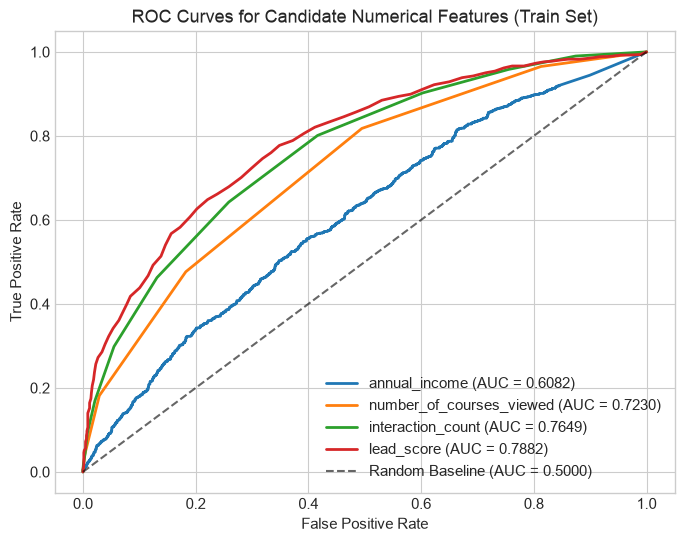

ROC AUC for candidate numerical features:


,Feature,ROC AUC
0,lead_score,0.788225
1,interaction_count,0.764920
2,number_of_courses_viewed,0.722989
3,annual_income,0.608198



Feature with highest AUC: lead_score (AUC = 0.7882)


In [4]:
candidate_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]

single_feature_auc = {}

plt.figure(figsize=(8, 6))

for col in numerical_features:
    raw_auc = roc_auc_score(y_train, df_train[col])
    # If AUC < 0.5, invert feature
    adjusted_auc = max(raw_auc, 1.0 - raw_auc)
    single_feature_auc[col] = adjusted_auc
    
    # Plot ROC curve for candidate features
    if col in candidate_features:
        # Determine score orientation
        score = df_train[col] if raw_auc >= 0.5 else -df_train[col]
        fpr, tpr, _ = roc_curve(y_train, score)
        plt.plot(fpr, tpr, label=f"{col} (AUC = {adjusted_auc:.4f})", linewidth=2)

plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Baseline (AUC = 0.5000)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Candidate Numerical Features (Train Set)")
plt.legend(loc="lower right")
plt.show()

# Display results table
q1_df = pd.DataFrame([
    {"Feature": col, "ROC AUC": single_feature_auc[col]}
    for col in candidate_features
]).sort_values("ROC AUC", ascending=False).reset_index(drop=True)

print("ROC AUC for candidate numerical features:")
display(q1_df)

best_feature = max(candidate_features, key=single_feature_auc.get)
print(f"\nFeature with highest AUC: {best_feature} (AUC = {single_feature_auc[best_feature]:.4f})")


**Answer:** `lead_score` (ROC AUC: 0.7882)


---
### Question 2: Training the Model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:
```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)
- 0.532
- 0.632
- 0.732
- 0.832


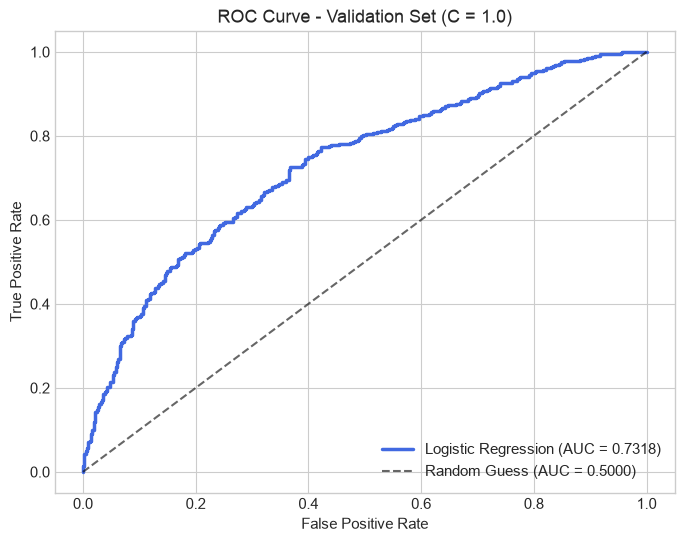

Validation ROC AUC (raw):     0.7318
Validation ROC AUC (rounded): 0.732


In [5]:
# One-hot encode using DictVectorizer
dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Train Logistic Regression model
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Predict probabilities on validation dataset
y_val_pred_proba = model.predict_proba(X_val)[:, 1]

# Compute ROC AUC
val_auc = roc_auc_score(y_val, y_val_pred_proba)

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_val, y_val_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {val_auc:.4f})", color="royalblue", linewidth=2.5)
plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (AUC = 0.5000)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set (C = 1.0)")
plt.legend(loc="lower right")
plt.show()

print(f"Validation ROC AUC (raw):     {val_auc:.4f}")
print(f"Validation ROC AUC (rounded): {val_auc:.3f}")


**Answer:** `0.732`


---
### Question 3: Precision and Recall

Now let's compute precision and recall for our model:
* Evaluate the model on all thresholds from `0.0` to `1.0` with step `0.01`.
* For each threshold, compute precision and recall.
* Plot them.

At which threshold do the precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.
- 0.43
- 0.63
- 0.73
- 0.83


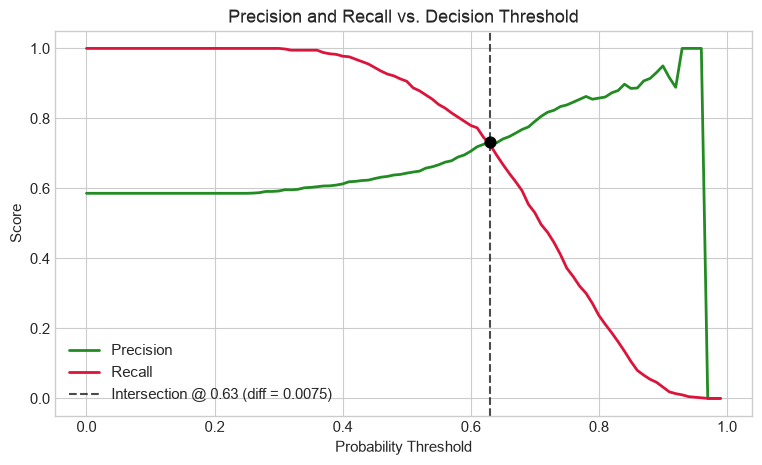

Thresholds with smallest |Precision - Recall| difference:


,Threshold,Precision,Recall,|Precision - Recall|
0,0.63,0.7328,0.7253,0.0075
1,0.62,0.7259,0.7457,0.0198
2,0.64,0.7299,0.6962,0.0336
3,0.61,0.7190,0.7730,0.0540
4,0.65,0.7410,0.6689,0.0721



Intersection threshold: 0.63


In [6]:
thresholds = np.arange(0.0, 1.0, 0.01)

precisions = []
recalls = []
diffs = []

for threshold in thresholds:
    y_pred = (y_val_pred_proba >= threshold).astype(int)
    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)
    
    precisions.append(p)
    recalls.append(r)
    
    if p == 0 and r == 0:
        diffs.append((np.inf, threshold, p, r))
    else:
        diffs.append((abs(p - r), threshold, p, r))

# Find threshold with minimal |precision - recall|
best_diff, intersect_threshold, best_p, best_r = min(diffs, key=lambda x: x[0])

# Plot Precision & Recall Curves
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label="Precision", color="forestgreen", linewidth=2)
plt.plot(thresholds, recalls, label="Recall", color="crimson", linewidth=2)
plt.axvline(x=intersect_threshold, color="black", linestyle="--", alpha=0.7, 
            label=f"Intersection @ {intersect_threshold:.2f} (diff = {best_diff:.4f})")
plt.scatter([intersect_threshold], [best_p], color="black", s=60, zorder=5)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Decision Threshold")
plt.legend(loc="best")
plt.show()

# Show top 5 closest thresholds
diffs_valid = [d for d in diffs if d[0] != np.inf]
diffs_valid.sort(key=lambda x: x[0])
closest_df = pd.DataFrame([
    {"Threshold": f"{t:.2f}", "Precision": f"{p:.4f}", "Recall": f"{r:.4f}", "|Precision - Recall|": f"{d:.4f}"}
    for d, t, p, r in diffs_valid[:5]
])
print("Thresholds with smallest |Precision - Recall| difference:")
display(closest_df)

print(f"\nIntersection threshold: {intersect_threshold:.2f}")


**Answer:** `0.63` (at threshold 0.63, Precision = 0.7328, Recall = 0.7253, difference = 0.0075)


---
### Question 4: F1 Score

Precision and recall are conflicting — when one grows, the other goes down. That's why they are often combined into the $F_1$ score:

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

Let's compute $F_1$ for all thresholds from `0.0` to `1.0` with increment `0.01`.

At which threshold is $F_1$ maximal?
- 0.21
- 0.41
- 0.61
- 0.81


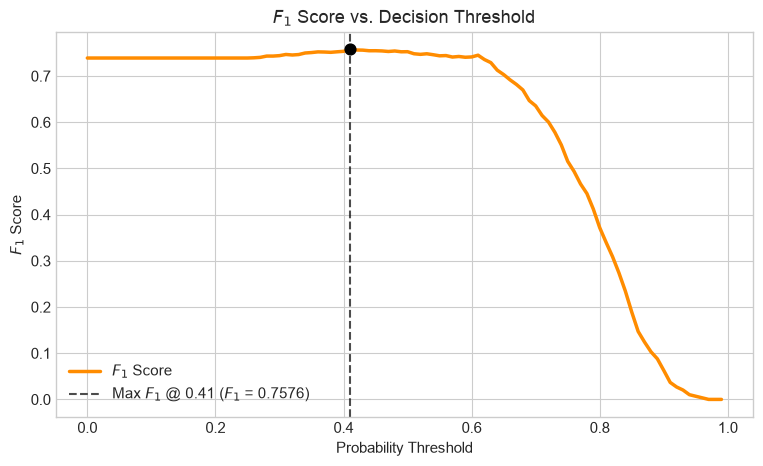

Thresholds with highest F1 scores:


,Threshold,F1 Score
0,0.41,0.7576
1,0.42,0.7563
2,0.43,0.7560
3,0.45,0.7548
4,0.44,0.7547



Optimal threshold for F1 score: 0.41 (F1 = 0.7576)


In [7]:
f1_scores = [
    f1_score(y_val, (y_val_pred_proba >= t).astype(int), zero_division=0)
    for t in thresholds
]

best_f1_idx = int(np.argmax(f1_scores))
best_f1_threshold = thresholds[best_f1_idx]
max_f1 = f1_scores[best_f1_idx]

# Plot F1 curve
plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1_scores, label="$F_1$ Score", color="darkorange", linewidth=2.5)
plt.axvline(x=best_f1_threshold, color="black", linestyle="--", alpha=0.7, 
            label=f"Max $F_1$ @ {best_f1_threshold:.2f} ($F_1$ = {max_f1:.4f})")
plt.scatter([best_f1_threshold], [max_f1], color="black", s=60, zorder=5)

plt.xlabel("Probability Threshold")
plt.ylabel("$F_1$ Score")
plt.title("$F_1$ Score vs. Decision Threshold")
plt.legend(loc="best")
plt.show()

# Show top 5 F1 thresholds
sorted_f1 = sorted(zip(thresholds, f1_scores), key=lambda x: x[1], reverse=True)
top_f1_df = pd.DataFrame([
    {"Threshold": f"{t:.2f}", "F1 Score": f"{score:.4f}"}
    for t, score in sorted_f1[:5]
])
print("Thresholds with highest F1 scores:")
display(top_f1_df)

print(f"\nOptimal threshold for F1 score: {best_f1_threshold:.2f} (F1 = {max_f1:.4f})")


**Answer:** `0.41` (maximal F1 score: 0.7576 at threshold 0.41)


---
### Question 5: 5-Fold Cross-Validation

Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:
```python
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use ROC AUC to evaluate the model on validation

How large is the standard deviation of the scores across different folds?
- 0.001
- 0.007
- 0.013
- 0.060


In [8]:
def fit_lead_model(train_x, train_y, val_x, c=1.0):
    dv = DictVectorizer(sparse=False)
    train_matrix = dv.fit_transform(train_x.to_dict(orient="records"))
    val_matrix = dv.transform(val_x.to_dict(orient="records"))
    
    model = LogisticRegression(solver="liblinear", C=c, max_iter=1000, random_state=42)
    model.fit(train_matrix, train_y)
    return model, val_matrix

cv = KFold(n_splits=5, shuffle=True, random_state=1)
cv_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(df_full_train), start=1):
    fold_train = df_full_train.iloc[train_idx].copy()
    fold_val = df_full_train.iloc[val_idx].copy()
    
    fold_train_y = fold_train.pop(TARGET).values
    fold_val_y = fold_val.pop(TARGET).values
    
    fold_model, fold_val_matrix = fit_lead_model(fold_train, fold_train_y, fold_val, c=1.0)
    y_pred = fold_model.predict_proba(fold_val_matrix)[:, 1]
    
    score = roc_auc_score(fold_val_y, y_pred)
    cv_scores.append(score)
    print(f"Fold {fold}: ROC AUC = {score:.4f}")

mean_cv = np.mean(cv_scores)
std_cv = np.std(cv_scores)

print(f"\n5-Fold Mean ROC AUC: {mean_cv:.4f}")
print(f"5-Fold Std ROC AUC (raw):     {std_cv:.4f}")
print(f"5-Fold Std ROC AUC (rounded): {std_cv:.3f}")


Fold 1: ROC AUC = 0.7306
Fold 2: ROC AUC = 0.7296
Fold 3: ROC AUC = 0.7363
Fold 4: ROC AUC = 0.7412


Fold 5: ROC AUC = 0.7209

5-Fold Mean ROC AUC: 0.7317
5-Fold Std ROC AUC (raw):     0.0069
5-Fold Std ROC AUC (rounded): 0.007


**Answer:** `0.007` (standard deviation: 0.0069 -> 0.007)


---
### Question 6: Hyperparameter Tuning ($C$)

Now let's use 5-Fold cross-validation to find the best parameter `C`:
* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously: `KFold(n_splits=5, shuffle=True, random_state=1)`
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round mean and std to 3 decimal digits).

Which `C` leads to the best mean ROC AUC?
- `0.000001`
- `0.001`
- `1`

*(If you have ties, select the score with the lowest std. If you still have ties, select the smallest C).*


In [9]:
c_values = [0.000001, 0.001, 1.0]
tuning_results = []

for c in c_values:
    scores = []
    for train_idx, val_idx in cv.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx].copy()
        fold_val = df_full_train.iloc[val_idx].copy()
        
        fold_train_y = fold_train.pop(TARGET).values
        fold_val_y = fold_val.pop(TARGET).values
        
        fold_model, fold_val_matrix = fit_lead_model(fold_train, fold_train_y, fold_val, c=c)
        y_pred = fold_model.predict_proba(fold_val_matrix)[:, 1]
        
        scores.append(roc_auc_score(fold_val_y, y_pred))
    
    mean_s = np.mean(scores)
    std_s = np.std(scores)
    tuning_results.append({
        "C": c,
        "Mean ROC AUC": round(mean_s, 4),
        "Std ROC AUC": round(std_s, 4),
        "Rounded Mean": round(mean_s, 3),
        "Rounded Std": round(std_s, 3),
    })

tuning_df = pd.DataFrame(tuning_results)
print("Hyperparameter tuning results:")
display(tuning_df)

# Selection criteria: highest round(mean, 3), lowest round(std, 3), smallest C
best_row = max(
    tuning_results, 
    key=lambda r: (r["Rounded Mean"], -r["Rounded Std"], -r["C"])
)

print(f"\nBest C: {best_row['C']} with Mean ROC AUC = {best_row['Mean ROC AUC']:.4f} (+/- {best_row['Std ROC AUC']:.4f})")


Hyperparameter tuning results:


,C,Mean ROC AUC,Std ROC AUC,Rounded Mean,Rounded Std
0,0.000001,0.6167,0.0187,0.617,0.019
1,0.001000,0.7492,0.0100,0.749,0.010
2,1.000000,0.7317,0.0069,0.732,0.007



Best C: 0.001 with Mean ROC AUC = 0.7492 (+/- 0.0100)


**Answer:** `0.001` (Mean ROC AUC: 0.7492, Std: 0.0100)


---
## Summary of Answers

| Question | Topic | Options | Selected Answer | Details |
|---|---|---|---|---|
| **Question 1** | ROC AUC Feature Importance | `lead_score`, `number_of_courses_viewed`, `interaction_count`, `annual_income` | **`lead_score`** | ROC AUC = 0.7882 |
| **Question 2** | Model Validation ROC AUC | 0.532, 0.632, 0.732, 0.832 | **0.732** | Validation AUC = 0.7318 |
| **Question 3** | Precision & Recall Intersection | 0.43, 0.63, 0.73, 0.83 | **0.63** | Smallest diff \|P - R\| = 0.0075 |
| **Question 4** | Maximum F1 Score Threshold | 0.21, 0.41, 0.61, 0.81 | **0.41** | Maximal F1 = 0.7576 |
| **Question 5** | 5-Fold CV Standard Deviation | 0.001, 0.007, 0.013, 0.060 | **0.007** | Fold std = 0.0069 -> 0.007 |
| **Question 6** | Best Hyperparameter $C$ | 0.000001, 0.001, 1 | **0.001** | Mean AUC = 0.7492 |
